In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
df = pd.read_csv("social_media_engagement_5000.csv")

In [4]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [5]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [6]:
df.shape

(5000, 19)

In [8]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [9]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [11]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    dayfirst=True
)

In [12]:
df['posted_at'].dtypes

dtype('<M8[ns]')

In [13]:
likes_array = np.array(df['likes'].dropna())

In [14]:
print(likes_array[:10])

[ 7011. 11750.  4862.  5350. 12682. 12535. 11703.  9611. 14106.   355.]


In [15]:
print("Average Likes:", np.mean(likes_array))

Average Likes: 10107.043711340206


In [16]:
print("Minimum Likes:", np.min(likes_array))
print("Maximum Likes:", np.max(likes_array))
print("Standard Deviation:", np.std(likes_array))

Minimum Likes: 10.0
Maximum Likes: 19998.0
Standard Deviation: 5789.222332204696


In [17]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


In [18]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 900


In [19]:
numeric_columns = [
    'age',
    'likes',
    'comments',
    'shares'
]

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

In [20]:
categorical_columns = [
    'gender',
    'sentiment'
]

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

In [21]:
print(df.isnull().sum())

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64


In [22]:
df_ffill = df.fillna(method='ffill')

/tmp/ipykernel_3153/1858979379.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_ffill = df.fillna(method='ffill')


In [23]:
df_bfill = df.fillna(method='bfill')

/tmp/ipykernel_3153/500893343.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_bfill = df.fillna(method='bfill')


In [24]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [25]:
df = df.drop_duplicates()

In [26]:
print(df.shape)

(5000, 19)


In [27]:
print("Negative ages:", (df['age'] < 0).sum())
print("Negative likes:", (df['likes'] < 0).sum())
print("Negative comments:", (df['comments'] < 0).sum())
print("Negative shares:", (df['shares'] < 0).sum())

Negative ages: 0
Negative likes: 0
Negative comments: 0
Negative shares: 0


In [28]:
print(df['age'].min())
print(df['age'].max())

13.0
64.0


In [29]:
print(df['gender'].unique())

['Female' 'Male' 'Other']


In [30]:
df['gender'] = df['gender'].str.strip().str.title()

In [31]:
print(df['sentiment'].unique())

['negative' 'positive' 'neutral']


In [32]:
df['sentiment'] = df['sentiment'].str.strip().str.lower()

In [33]:
df['post_type'] = df['post_type'].str.strip().str.lower()

In [34]:
df['post_category'] = df['post_category'].str.strip().str.lower()

In [35]:
df['hashtag_count'] = df['hashtags'].str.split().str.len()

In [36]:
df[['hashtags', 'hashtag_count']].head()

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1


In [37]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [38]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [39]:
df.shape

(5000, 20)

In [40]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   float64       
 9   shares            5000 non-null   float64       
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [43]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [44]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [45]:
df['gender'].value_counts()

,count
gender,
Male,1849
Other,1581
Female,1570


In [46]:
df['country'].unique()

array(['Brazil', 'UK', 'France', 'Canada', 'Japan', 'Australia', 'India',
       'UAE', 'Germany', 'USA'], dtype=object)

In [47]:
df['country'].nunique()

10

In [48]:
print(df['post_type'].unique())
print(df['post_type'].nunique())
print(df['post_type'].value_counts())

['image' 'reel' 'text' 'video']
4
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64


In [49]:
print(df['post_category'].unique())
print(df['post_category'].nunique())
print(df['post_category'].value_counts())

['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']
8
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64


In [50]:
print(df['sentiment'].value_counts())
print(df['sentiment'].nunique())

sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64
3


In [51]:
numeric_columns = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate',
    'hashtag_count'
]

correlation_matrix = df[numeric_columns].corr()

print(correlation_matrix)

                       age     likes  comments    shares  watch_time_sec  \
age               1.000000 -0.036322 -0.007284  0.013871        0.005542   
likes            -0.036322  1.000000 -0.018421  0.004712        0.008710   
comments         -0.007284 -0.018421  1.000000  0.006142       -0.016351   
shares            0.013871  0.004712  0.006142  1.000000        0.014658   
watch_time_sec    0.005542  0.008710 -0.016351  0.014658        1.000000   
impression_count  0.013322  0.007952 -0.009395 -0.005204       -0.004335   
follower_count   -0.024894 -0.022982 -0.011733 -0.010783        0.002761   
engagement_rate   0.008039  0.093520  0.000051  0.021724       -0.001148   
hashtag_count     0.007173 -0.002190 -0.015230  0.013379       -0.023301   

                  impression_count  follower_count  engagement_rate  \
age                       0.013322       -0.024894         0.008039   
likes                     0.007952       -0.022982         0.093520   
comments                 -

In [52]:
avg_likes_post_type = df.groupby('post_type')['likes'].mean()

print(avg_likes_post_type)

post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64


In [56]:
avg_engagement_category = (
    df.groupby('post_category')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

print(avg_engagement_category)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64


In [58]:
country_engagement = (
    df.groupby('country')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

print(country_engagement)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


In [59]:
df['engagement_score'] = (
    df['likes'] +
    df['comments'] +
    df['shares']
)

In [60]:
df['year'] = df['posted_at'].dt.year
df['month'] = df['posted_at'].dt.month
df['day'] = df['posted_at'].dt.day
df['weekday'] = df['posted_at'].dt.day_name()
df['hour'] = df['posted_at'].dt.hour

In [61]:
sentiment_summary = df.groupby('sentiment').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'
})

print(sentiment_summary)

                  likes     comments       shares  engagement_score  \
sentiment                                                             
negative   10208.096875  1516.094792  1007.307292      12731.498958   
neutral     9923.194499  1528.404060   996.565160      12448.163720   
positive   10180.062077  1480.650617  1005.086749      12665.799443   

           engagement_rate  
sentiment                   
negative          1.038486  
neutral           0.991170  
positive          0.919744  


In [62]:
country_summary = df.groupby('country').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_rate': 'mean'
}).sort_values(
    'engagement_rate',
    ascending=False
)

print(country_summary)

                  likes     comments       shares  engagement_rate
country                                                           
Brazil      9886.689484  1490.434524  1008.859127         1.540704
Australia  10294.124746  1485.803245  1029.693712         1.324339
France     10372.876008  1478.695565  1051.812500         1.146402
UAE        10227.487078  1541.214712   989.075547         1.112352
Canada     10063.066277  1546.582846   996.245614         0.916659
UK          9935.650101  1463.042596   985.681542         0.850966
Japan      10088.862288  1530.434322   959.351695         0.769623
Germany    10130.458163  1531.826531   973.379592         0.759000
India       9962.468224  1494.917757  1035.315888         0.655005
USA        10122.361277  1457.958084   995.141717         0.576580


In [63]:
post_type_summary = df.groupby('post_type').agg({
    'likes': 'mean',
    'comments': 'mean',
    'shares': 'mean',
    'engagement_score': 'mean',
    'engagement_rate': 'mean'
}).sort_values(
    'engagement_rate',
    ascending=False
)

print(post_type_summary)

                  likes     comments       shares  engagement_score  \
post_type                                                             
video      10188.600000  1479.160000   996.834286      12664.594286   
text       10100.148193  1499.106024  1013.989558      12613.243775   
image      10104.865277  1525.235766  1019.289495      12649.390537   
reel       10037.802416  1504.187062   982.042089      12524.031567   

           engagement_rate  
post_type                   
video             1.122365  
text              1.064549  
image             0.895646  
reel              0.783047  


In [64]:
stats_columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

In [65]:
for column in stats_columns:
    print(column, "Mean =", df[column].mean())

likes Mean = 10106.9974
comments Mean = 1502.0398
shares Mean = 1002.9106
watch_time_sec Mean = 4014.5032
engagement_rate Mean = 0.9643560291583999
follower_count Mean = 393698.2248


In [66]:
for column in stats_columns:
    print(column, "Median =", df[column].median())

likes Median = 10105.5
comments Median = 1497.0
shares Median = 1012.0
watch_time_sec Median = 4034.5
engagement_rate Median = 0.2538959065
follower_count Median = 388982.0


In [67]:
for column in stats_columns:
    print(column, "Mode =", df[column].mode()[0])

likes Mode = 10105.5
comments Mode = 1497.0
shares Mode = 1012.0
watch_time_sec Mode = 916
engagement_rate Mode = 0.006362909
follower_count Mode = 497502


In [68]:
for column in stats_columns:
    print(column, "Standard Deviation =", df[column].std())

likes Standard Deviation = 5702.293017183876
comments Standard Deviation = 856.3933120458967
shares Standard Deviation = 570.8551999758862
watch_time_sec Standard Deviation = 2308.096459042085
engagement_rate Standard Deviation = 5.318029222661535
follower_count Standard Deviation = 230927.88453461014


In [69]:
for column in stats_columns:
    print(column, "Variance =", df[column].var())

likes Variance = 32516145.653823998
comments Variance = 733409.5049169405
shares Variance = 325875.65933950903
watch_time_sec Variance = 5327309.26424261
engagement_rate Variance = 28.281434813082043
follower_count Variance = 53327687855.63023


In [70]:
for column in stats_columns:
    print("\n", column)
    print("25th percentile:", df[column].quantile(0.25))
    print("50th percentile:", df[column].quantile(0.50))
    print("75th percentile:", df[column].quantile(0.75))


 likes
25th percentile: 5235.0
50th percentile: 10105.5
75th percentile: 14959.0

 comments
25th percentile: 792.0
50th percentile: 1497.0
75th percentile: 2235.25

 shares
25th percentile: 511.0
50th percentile: 1012.0
75th percentile: 1483.0

 watch_time_sec
25th percentile: 2017.75
50th percentile: 4034.5
75th percentile: 6020.25

 engagement_rate
25th percentile: 0.14578108750000002
50th percentile: 0.2538959065
75th percentile: 0.504793702

 follower_count
25th percentile: 194480.0
50th percentile: 388982.0
75th percentile: 589744.25


In [71]:
for column in stats_columns:
    print(column, "Skewness =", df[column].skew())

likes Skewness = -0.006893616532184278
comments Skewness = 0.0038017289479831415
shares Skewness = -0.014653583910311461
watch_time_sec Skewness = -0.018196273193231846
engagement_rate Skewness = 18.781270878869154
follower_count Skewness = 0.04111777394961326


In [72]:
for column in stats_columns:
    print(column, "Kurtosis =", df[column].kurt())

likes Kurtosis = -1.1499923609078424
comments Kurtosis = -1.1443748352968992
shares Kurtosis = -1.1468565626589917
watch_time_sec Kurtosis = -1.195651797070188
engagement_rate Kurtosis = 482.9917386319569
follower_count Kurtosis = -1.1894740478821386


In [73]:
statistical_summary = pd.DataFrame({
    'Mean': df[stats_columns].mean(),
    'Median': df[stats_columns].median(),
    'Mode': df[stats_columns].mode().iloc[0],
    'Standard Deviation': df[stats_columns].std(),
    'Variance': df[stats_columns].var(),
    '25th Percentile': df[stats_columns].quantile(0.25),
    '50th Percentile': df[stats_columns].quantile(0.50),
    '75th Percentile': df[stats_columns].quantile(0.75),
    'Skewness': df[stats_columns].skew(),
    'Kurtosis': df[stats_columns].kurt()
})

print(statistical_summary)

                          Mean         Median           Mode  \
likes             10106.997400   10105.500000   10105.500000   
comments           1502.039800    1497.000000    1497.000000   
shares             1002.910600    1012.000000    1012.000000   
watch_time_sec     4014.503200    4034.500000     916.000000   
engagement_rate       0.964356       0.253896       0.006363   
follower_count   393698.224800  388982.000000  497502.000000   

                 Standard Deviation      Variance  25th Percentile  \
likes                   5702.293017  3.251615e+07      5235.000000   
comments                 856.393312  7.334095e+05       792.000000   
shares                   570.855200  3.258757e+05       511.000000   
watch_time_sec          2308.096459  5.327309e+06      2017.750000   
engagement_rate            5.318029  2.828143e+01         0.145781   
follower_count        230927.884535  5.332769e+10    194480.000000   

                 50th Percentile  75th Percentile   Skewness

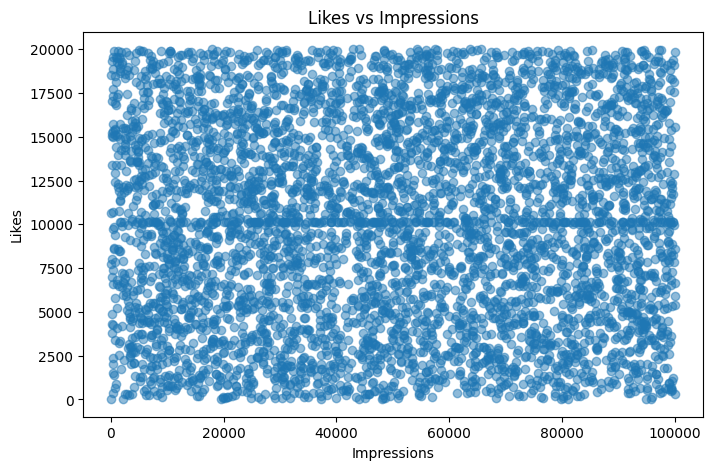

In [74]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['impression_count'],
    df['likes'],
    alpha=0.5
)

plt.xlabel('Impressions')
plt.ylabel('Likes')
plt.title('Likes vs Impressions')

plt.show()

In [75]:
daily_engagement = (
    df.groupby('posted_at')['engagement_score']
    .mean()
    .reset_index()
)

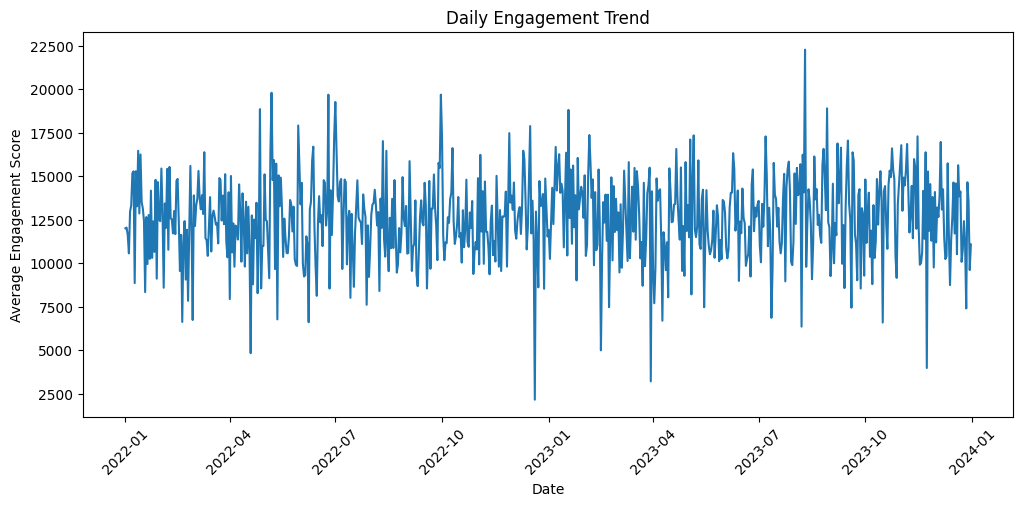

In [76]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_engagement['posted_at'],
    daily_engagement['engagement_score']
)

plt.xlabel('Date')
plt.ylabel('Average Engagement Score')
plt.title('Daily Engagement Trend')

plt.xticks(rotation=45)

plt.show()

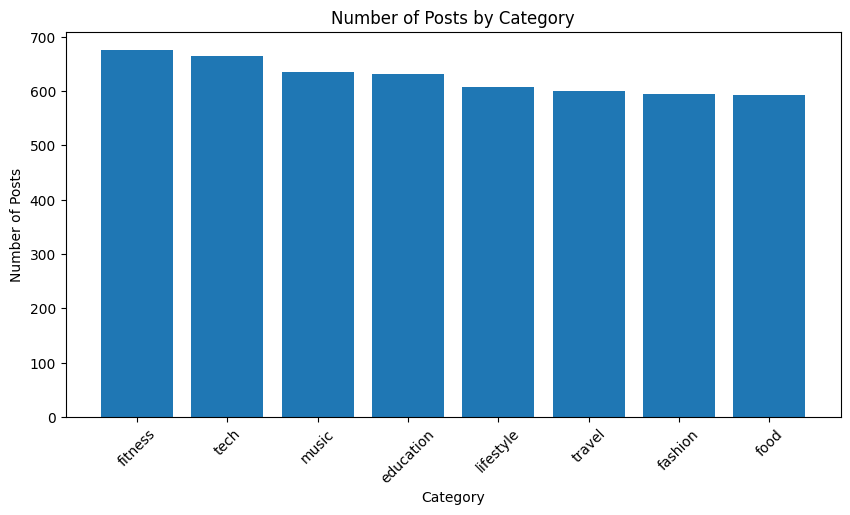

In [77]:
category_counts = df['post_category'].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(
    category_counts.index,
    category_counts.values
)

plt.xlabel('Category')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Category')

plt.xticks(rotation=45)

plt.show()

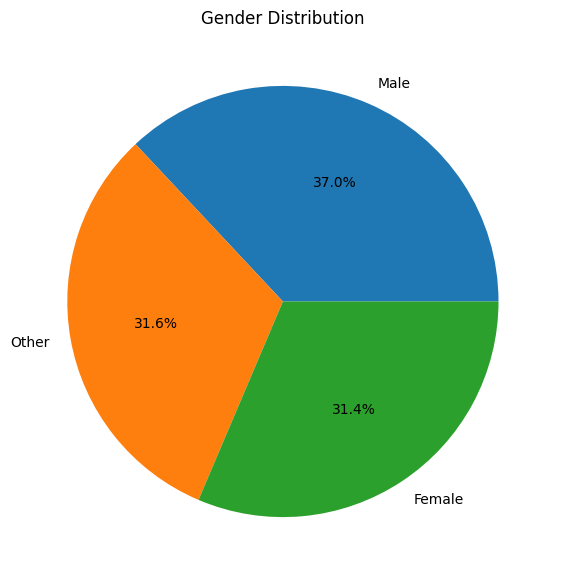

In [78]:
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')

plt.show()

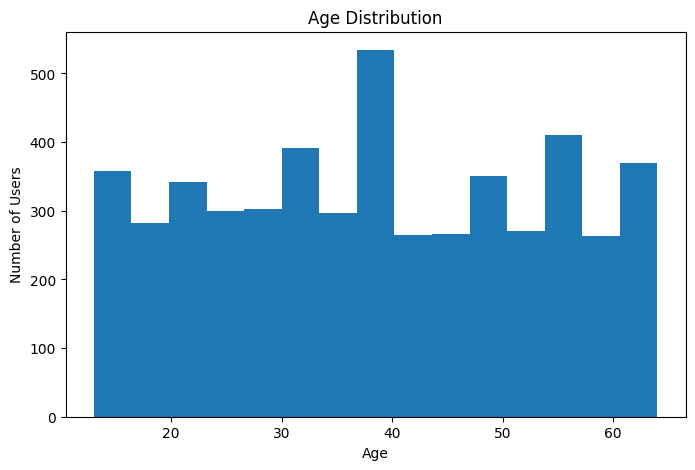

In [80]:
plt.figure(figsize=(8, 5))

plt.hist(
    df['age'],
    bins=15
)

plt.xlabel('Age')
plt.ylabel('Number of Users')
plt.title('Age Distribution')

plt.show()

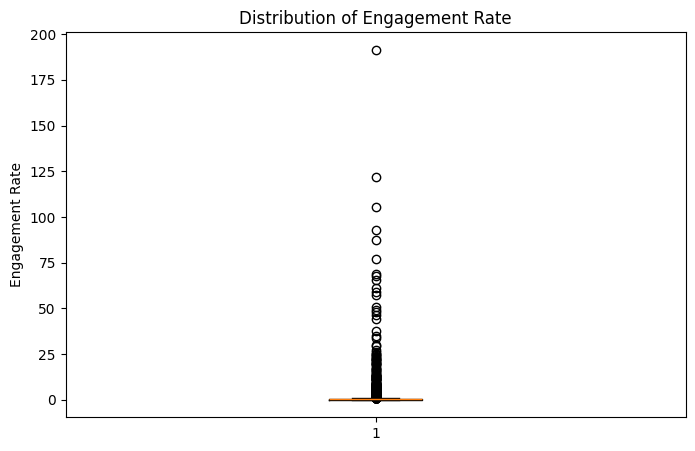

In [81]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    df['engagement_rate']
)

plt.ylabel('Engagement Rate')
plt.title('Distribution of Engagement Rate')

plt.show()

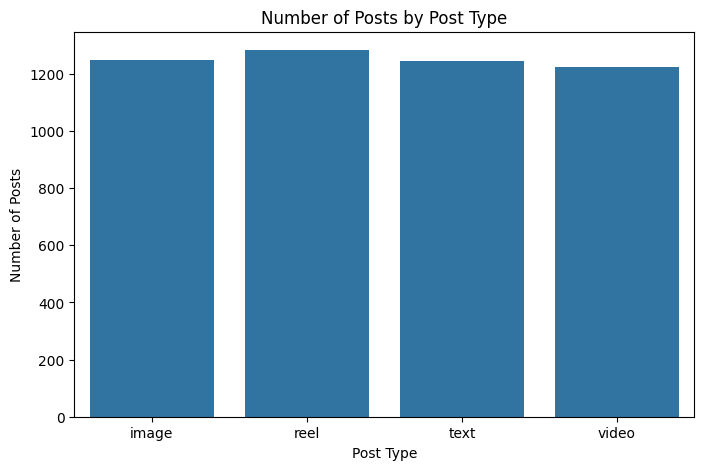

In [82]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='post_type'
)

plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.title('Number of Posts by Post Type')

plt.show()

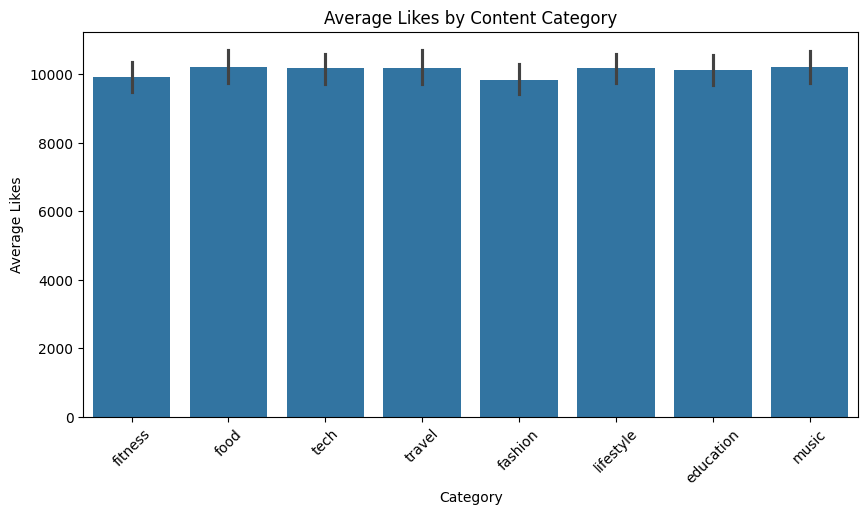

In [83]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes',
    estimator='mean'
)

plt.xlabel('Category')
plt.ylabel('Average Likes')
plt.title('Average Likes by Content Category')

plt.xticks(rotation=45)

plt.show()

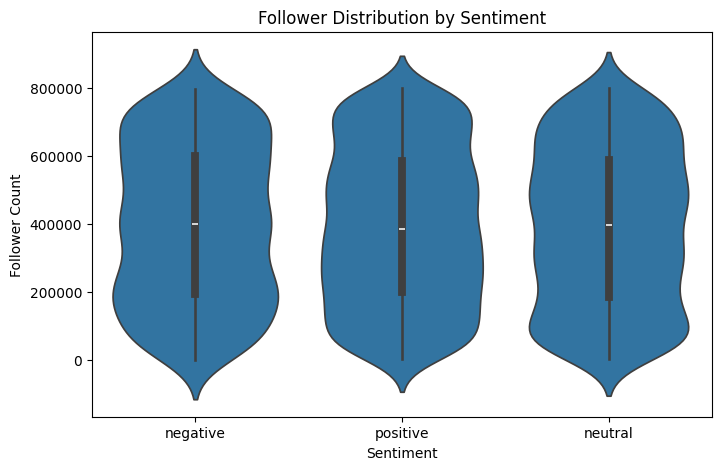

In [84]:
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.title('Follower Distribution by Sentiment')

plt.show()

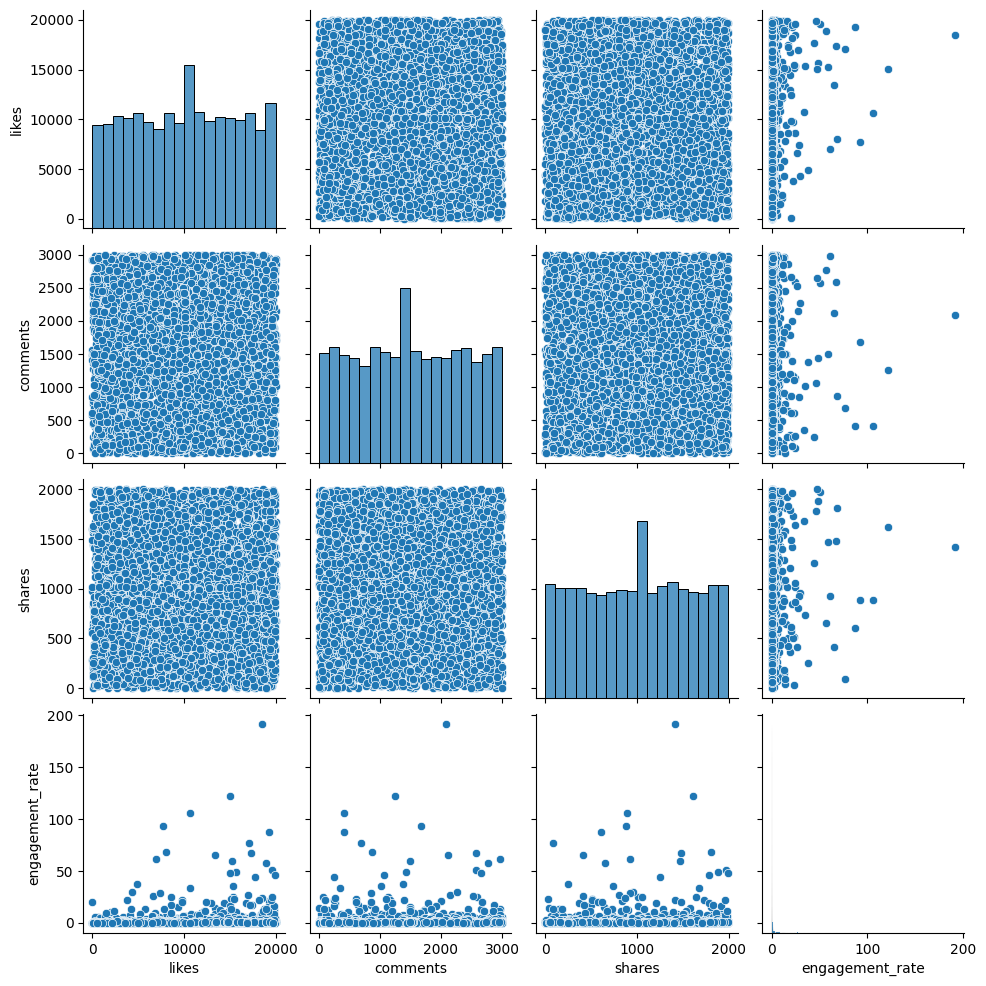

In [85]:
pair_columns = [
    'likes',
    'comments',
    'shares',
    'engagement_rate'
]

sns.pairplot(
    df[pair_columns]
)

plt.show()

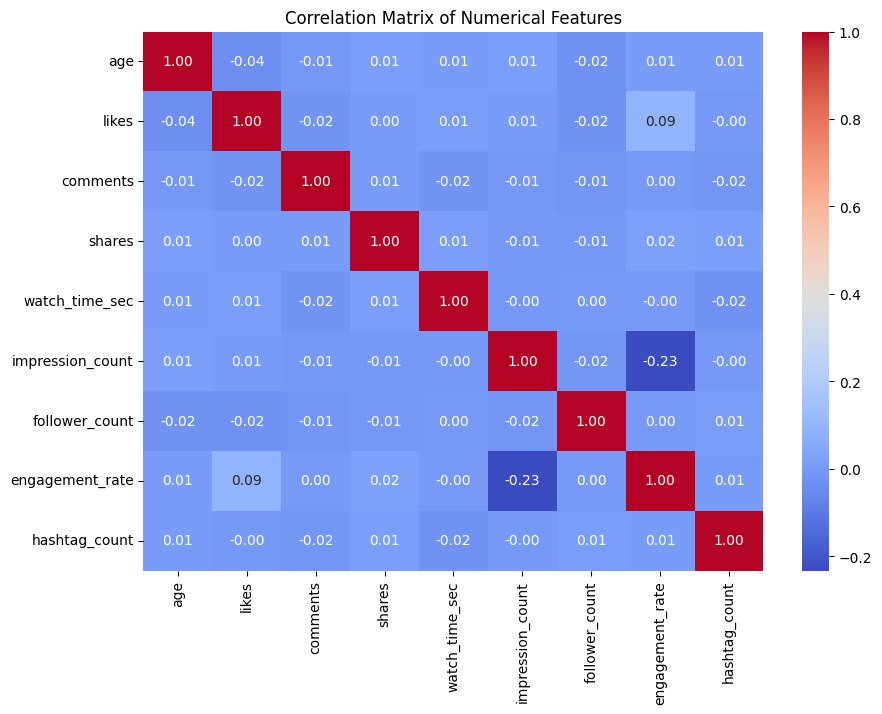

In [86]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Features')

plt.show()

In [87]:
sample_df = df.sample(
    500,
    random_state=42
)

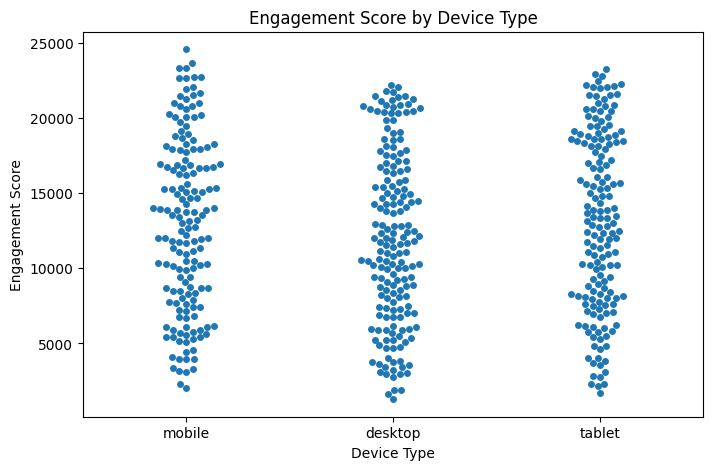

In [88]:
plt.figure(figsize=(8, 5))

sns.swarmplot(
    data=sample_df,
    x='device_type',
    y='engagement_score'
)

plt.xlabel('Device Type')
plt.ylabel('Engagement Score')
plt.title('Engagement Score by Device Type')

plt.show()

In [89]:
daily_engagement = (
    df.groupby('posted_at')['engagement_score']
    .mean()
    .reset_index()
)

fig = px.line(
    daily_engagement,
    x='posted_at',
    y='engagement_score',
    title='Interactive Daily Engagement Trend'
)

fig.show()

In [90]:
post_type_result = (
    df.groupby('post_type')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

print(post_type_result)

print(
    "Best post type:",
    post_type_result.idxmax()
)

print(
    "Highest average engagement rate:",
    post_type_result.max()
)

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64
Best post type: video
Highest average engagement rate: 1.122365000962449


In [91]:
category_result = (
    df.groupby('post_category')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

print(category_result)

print(
    "Best content category:",
    category_result.idxmax()
)

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64
Best content category: food


In [92]:
country_result = (
    df.groupby('country')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

print(country_result)

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
UK           0.850966
Japan        0.769623
Germany      0.759000
India        0.655005
USA          0.576580
Name: engagement_rate, dtype: float64


In [93]:
print(country_result.head(5))

country
Brazil       1.540704
Australia    1.324339
France       1.146402
UAE          1.112352
Canada       0.916659
Name: engagement_rate, dtype: float64


In [94]:
age_engagement_corr = df[
    ['age', 'engagement_rate']
].corr()

print(age_engagement_corr)

                      age  engagement_rate
age              1.000000         0.008039
engagement_rate  0.008039         1.000000


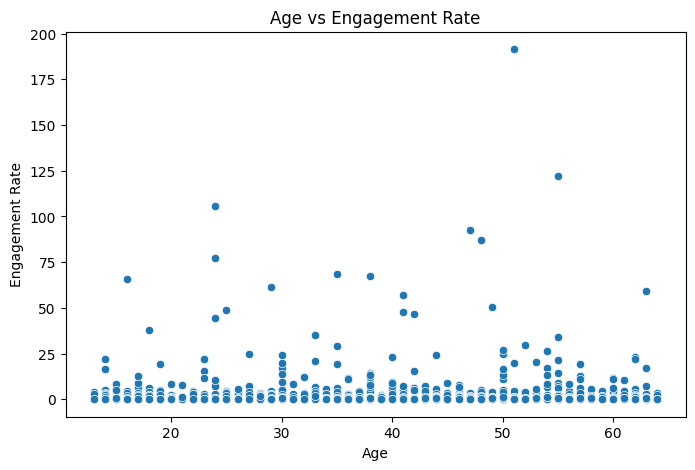

In [95]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='age',
    y='engagement_rate'
)

plt.xlabel('Age')
plt.ylabel('Engagement Rate')
plt.title('Age vs Engagement Rate')

plt.show()

In [96]:
verified_result = (
    df.groupby('is_verified')['engagement_rate']
    .mean()
)

print(verified_result)

is_verified
False    0.954744
True     1.054250
Name: engagement_rate, dtype: float64


In [97]:
verified_result.index = verified_result.index.map({
    True: 'Verified',
    False: 'Not Verified'
})

print(verified_result)

is_verified
Not Verified    0.954744
Verified        1.054250
Name: engagement_rate, dtype: float64


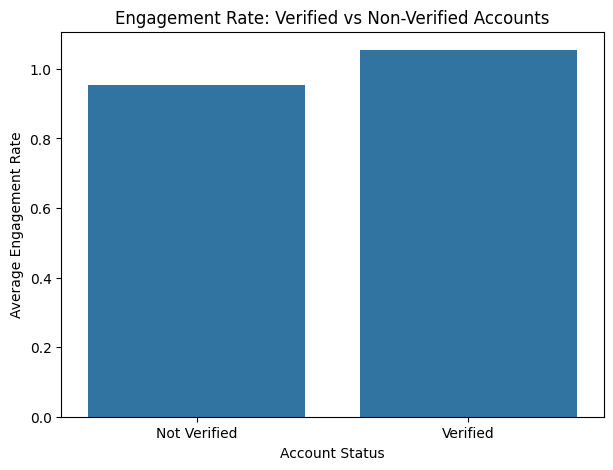

In [98]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=verified_result.index,
    y=verified_result.values
)

plt.xlabel('Account Status')
plt.ylabel('Average Engagement Rate')
plt.title('Engagement Rate: Verified vs Non-Verified Accounts')

plt.show()

In [99]:
device_watch = (
    df.groupby('device_type')['watch_time_sec']
    .mean()
    .sort_values(ascending=False)
)

print(device_watch)

device_type
mobile     4087.830760
tablet     3979.736429
desktop    3974.792521
Name: watch_time_sec, dtype: float64


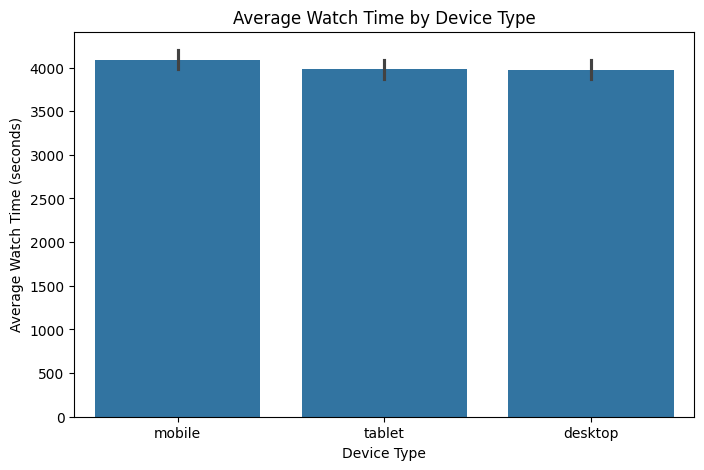

In [100]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='device_type',
    y='watch_time_sec',
    estimator='mean'
)

plt.xlabel('Device Type')
plt.ylabel('Average Watch Time (seconds)')
plt.title('Average Watch Time by Device Type')

plt.show()

In [101]:
sentiment_result = (
    df.groupby('sentiment')['engagement_rate']
    .mean()
    .sort_values(ascending=False)
)

print(sentiment_result)

print(
    "Best-performing sentiment:",
    sentiment_result.idxmax()
)

sentiment
negative    1.038486
neutral     0.991170
positive    0.919744
Name: engagement_rate, dtype: float64
Best-performing sentiment: negative


In [102]:
negative_neutral = df[
    df['sentiment'].isin(['negative', 'neutral'])
]

negative_neutral_result = (
    negative_neutral
    .groupby('sentiment')
    .agg({
        'likes': 'mean',
        'comments': 'mean',
        'shares': 'mean',
        'engagement_score': 'mean',
        'engagement_rate': 'mean'
    })
)

print(negative_neutral_result)

                  likes     comments       shares  engagement_score  \
sentiment                                                             
negative   10208.096875  1516.094792  1007.307292      12731.498958   
neutral     9923.194499  1528.404060   996.565160      12448.163720   

           engagement_rate  
sentiment                   
negative          1.038486  
neutral           0.991170  


In [103]:
final_summary = df.groupby('post_type').agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_rate', 'mean'),
    average_watch_time=('watch_time_sec', 'mean')
).sort_values(
    'average_engagement',
    ascending=False
)

print(final_summary)

           average_likes  average_comments  average_shares  \
post_type                                                    
video       10188.600000       1479.160000      996.834286   
text        10100.148193       1499.106024     1013.989558   
image       10104.865277       1525.235766     1019.289495   
reel        10037.802416       1504.187062      982.042089   

           average_engagement  average_watch_time  
post_type                                          
video                1.122365         4026.673469  
text                 1.064549         4010.873092  
image                0.895646         3881.448276  
reel                 0.783047         4135.727202  


In [104]:
df.to_csv(
    'social_media_engagement_cleaned.csv',
    index=False
)